# Phân loại RT_IOT2022: Random Forest và Neural Network

Notebook này sử dụng `rt_iot_eda_outputs/train.csv.gz` và `test.csv.gz` đã tạo ở bước EDA. Random Forest là thuật toán classification dạng cây; MLPClassifier là mạng neural network nhiều lớp. Chọn mô hình bằng macro-F1 trên validation tách từ train, fit lại trên toàn bộ train và chỉ đánh giá test ở bước cuối.

In [4]:
from pathlib import Path
import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, classification_report, ConfusionMatrixDisplay,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
TARGET = 'Attack_type'
OUTPUT_DIR = Path('rt_iot_eda_outputs')
MODEL_DIR = OUTPUT_DIR / 'models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
train = pd.read_csv(OUTPUT_DIR / 'train.csv.gz')
test = pd.read_csv(OUTPUT_DIR / 'test.csv.gz')
X_train_full, y_train_full = train.drop(columns=TARGET), train[TARGET]
X_test, y_test = test.drop(columns=TARGET), test[TARGET]
assert set(y_train_full) == set(y_test), 'Train/test không có cùng tập nhãn.'
assert X_train_full.columns.tolist() == X_test.columns.tolist(), 'Train/test lệch cột.'
print(f'Train: {X_train_full.shape}; test: {X_test.shape}; số lớp: {y_train_full.nunique()}')
display(y_train_full.value_counts().rename('Số mẫu train').to_frame())

Train: (98490, 83); test: (24623, 83); số lớp: 12


,Số mẫu train
Attack_type,
DOS_SYN_Hping,75727
Thing_Speak,6485
ARP_poisioning,6198
MQTT_Publish,3317
NMAP_UDP_SCAN,2072
NMAP_XMAS_TREE_SCAN,1608
NMAP_OS_DETECTION,1600
NMAP_TCP_scan,802
DDOS_Slowloris,427


## 1. Tạo validation và bộ tiền xử lý

Validation được trích phân tầng từ train. Mỗi pipeline tự fit encoder và scaler chỉ trên phần train tương ứng; test chưa được dùng.

In [5]:
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train_full, y_train_full, test_size=0.15, random_state=RANDOM_STATE, stratify=y_train_full
)
cat_cols = X_fit.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X_fit.select_dtypes(include='number').columns.tolist()
print(f'Fit: {X_fit.shape}; validation: {X_valid.shape}')
print(f'{len(num_cols)} biến số, {len(cat_cols)} biến phân loại: {cat_cols}')

def make_preprocessor(scale_numeric):
    numeric_steps = 'passthrough'
    if scale_numeric:
        numeric_steps = Pipeline([
            ('log1p', FunctionTransformer(np.log1p, validate=False)),
            ('scale', StandardScaler()),
        ])
    return ColumnTransformer([
        ('num', numeric_steps, num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ], remainder='drop', sparse_threshold=0)

models = {
    'Random Forest': Pipeline([
        ('preprocess', make_preprocessor(scale_numeric=False)),
        ('model', RandomForestClassifier(
            n_estimators=250, class_weight='balanced_subsample',
            min_samples_leaf=1, n_jobs=-1, random_state=RANDOM_STATE
        )),
    ]),
    'Neural Network (MLP)': Pipeline([
        ('preprocess', make_preprocessor(scale_numeric=True)),
        ('model', MLPClassifier(
            hidden_layer_sizes=(128, 64), activation='relu', solver='adam',
            alpha=1e-4, batch_size=1024, learning_rate_init=1e-3,
            early_stopping=False, validation_fraction=0.1, n_iter_no_change=5,
            max_iter=40, random_state=RANDOM_STATE, verbose=False
        )),
    ]),
}

validation_results = []
for name, pipeline in models.items():
    started = time.perf_counter()
    pipeline.fit(X_fit, y_fit)
    prediction = pipeline.predict(X_valid)
    elapsed = time.perf_counter() - started
    validation_results.append({
        'Mô hình': name,
        'Accuracy': accuracy_score(y_valid, prediction),
        'Macro F1': f1_score(y_valid, prediction, average='macro', zero_division=0),
        'Weighted F1': f1_score(y_valid, prediction, average='weighted', zero_division=0),
        'Thời gian (giây)': round(elapsed, 1),
    })

validation_results = pd.DataFrame(validation_results).sort_values('Macro F1', ascending=False)
display(validation_results.round(4))
best_name = validation_results.iloc[0]['Mô hình']
print(f'Mô hình được chọn theo Macro F1 validation: {best_name}')

Fit: (83716, 83); validation: (14774, 83)
81 biến số, 2 biến phân loại: ['proto', 'service']


d:\Programdata2026\Anaconda3\envs\sgu_ml\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (40) reached and the optimization hasn't converged yet.
  warnings.warn(


,Mô hình,Accuracy,Macro F1,Weighted F1,Thời gian (giây)
0,Random Forest,0.9991,0.9951,0.9991,8.1
1,Neural Network (MLP),0.9981,0.9791,0.9981,19.3


Mô hình được chọn theo Macro F1 validation: Random Forest


## 2. Fit mô hình được chọn và đánh giá test

Sau khi chọn bằng validation, tạo pipeline mới và fit trên toàn bộ train. Test chỉ được dùng ở đây cho đánh giá cuối cùng; không dùng để đổi cấu hình.

Kết quả trên TEST (đánh giá cuối cùng):


,Giá trị
model,Random Forest
accuracy,0.998985
macro_f1,0.97728
weighted_f1,0.998983
macro_precision,0.984521
macro_recall,0.97097


,precision,recall,f1-score,support
ARP_poisioning,0.9916,0.9948,0.9932,1550.000
DDOS_Slowloris,1.0000,0.9813,0.9906,107.000
DOS_SYN_Hping,1.0000,1.0000,1.0000,18932.000
MQTT_Publish,1.0000,0.9988,0.9994,829.000
Metasploit_Brute_Force_SSH,1.0000,0.8571,0.9231,7.000
NMAP_FIN_SCAN,0.8333,0.8333,0.8333,6.000
NMAP_OS_DETECTION,1.0000,1.0000,1.0000,400.000
NMAP_TCP_scan,1.0000,1.0000,1.0000,200.000
NMAP_UDP_SCAN,0.9942,0.9961,0.9952,518.000
NMAP_XMAS_TREE_SCAN,1.0000,0.9950,0.9975,402.000


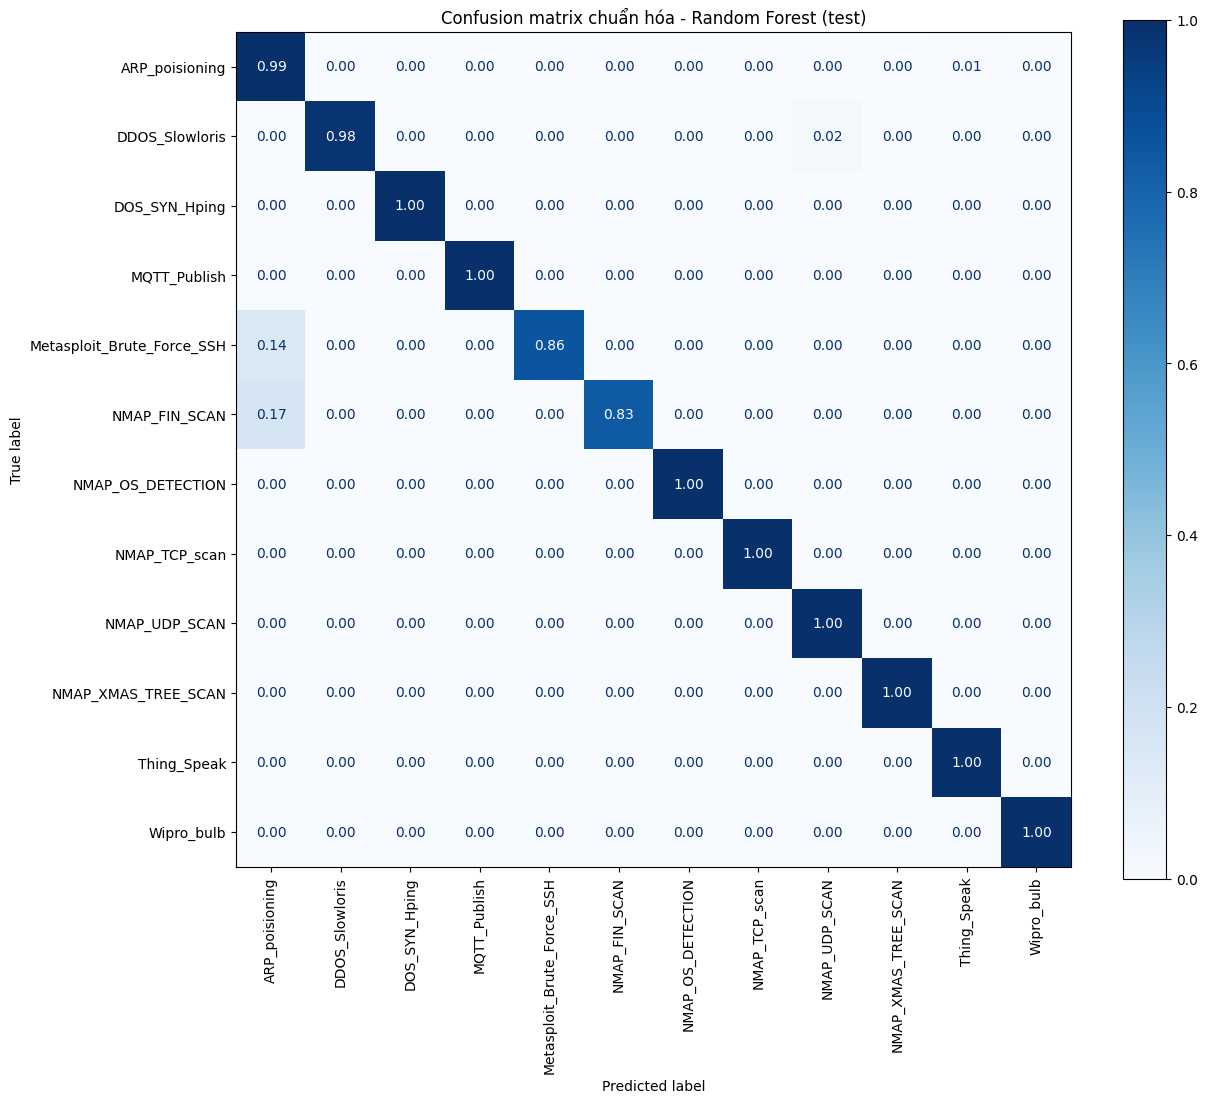

In [6]:
best_model = models[best_name]
best_model.fit(X_train_full, y_train_full)
test_prediction = best_model.predict(X_test)
labels = sorted(y_train_full.unique())
test_metrics = {
    'model': best_name,
    'accuracy': float(accuracy_score(y_test, test_prediction)),
    'macro_f1': float(f1_score(y_test, test_prediction, average='macro', zero_division=0)),
    'weighted_f1': float(f1_score(y_test, test_prediction, average='weighted', zero_division=0)),
    'macro_precision': float(precision_score(y_test, test_prediction, average='macro', zero_division=0)),
    'macro_recall': float(recall_score(y_test, test_prediction, average='macro', zero_division=0)),
}
print('Kết quả trên TEST (đánh giá cuối cùng):')
display(pd.Series(test_metrics, name='Giá trị').to_frame().round(4))
report = classification_report(y_test, test_prediction, labels=labels, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T
display(report_df.round(4))
report_df.to_csv(MODEL_DIR / 'classification_report_test.csv', encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(13, 11))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_prediction, labels=labels, display_labels=labels,
    normalize='true', values_format='.2f', xticks_rotation=90, cmap='Blues', ax=ax
)
ax.set_title(f'Confusion matrix chuẩn hóa - {best_name} (test)')
fig.tight_layout()
fig.savefig(MODEL_DIR / 'confusion_matrix_test.png', dpi=160, bbox_inches='tight')
plt.show()

## 3. Lưu mô hình và kết quả

Mô hình đã gồm preprocessing nên có thể nạp lại và dự đoán trên dữ liệu thô cùng schema. Lưu cả kết quả validation, metric test và dự đoán test để phục vụ báo cáo.

In [7]:
model_path = MODEL_DIR / 'best_model.joblib'
joblib.dump(best_model, model_path, compress=3)
(MODEL_DIR / 'metrics.json').write_text(
    json.dumps({
        'selected_model': best_name,
        'selection_metric': 'validation_macro_f1',
        'validation_results': validation_results.to_dict(orient='records'),
        'test_metrics': test_metrics,
        'random_state': RANDOM_STATE,
        'target': TARGET,
    }, indent=2, ensure_ascii=False),
    encoding='utf-8'
)
pd.DataFrame({
    'y_true': y_test.to_numpy(),
    'y_pred': test_prediction,
}).to_csv(MODEL_DIR / 'test_predictions.csv.gz', index=False, compression='gzip', encoding='utf-8-sig')
print('Đã lưu mô hình:', model_path)
print('Đã lưu metrics, classification report, confusion matrix và dự đoán test trong', MODEL_DIR.resolve())

Đã lưu mô hình: rt_iot_eda_outputs\models\best_model.joblib
Đã lưu metrics, classification report, confusion matrix và dự đoán test trong D:\sgu26_machine_learning\DoAnCK\RT_IOT2022_EDA_TienXuLy_TronBo\rt_iot_eda_outputs\models


## 4. Gom cụm bằng K-Means

Mô hình gom cụm chỉ fit trên các biến đầu vào trong train-fit; `Attack_type` không tham gia huấn luyện hay chọn k. Dùng Inertia để quan sát điểm khuỷu tay, Silhouette Score để đo độ tách biệt, rồi đọc quy mô, đặc trưng biến số và phân bố nhãn tham khảo của từng cụm. Nhãn chỉ được đối chiếu sau khi đã tạo cụm.

Với dải `k=2..20`, Silhouette cao nhất tại `k=14` (khoảng `0.780`) và giảm rõ ở `k=15`; Inertia bắt đầu giảm chậm hơn khoảng `k=5..8`. `k=14` tạo một cụm rất nhỏ (9 mẫu), vì vậy đây là ứng viên theo Silhouette chứ chưa chắc là số cụm phù hợp nhất. Hãy cân nhắc điểm khuỷu tay và kích thước/ý nghĩa từng cụm trước khi chốt.

Ứng viên k=14 có Silhouette Score cao nhất trong dải đã khảo sát.


,k,Inertia,Silhouette Score
0,2,990988.1468,0.7108
1,3,775643.8927,0.6167
2,4,619481.9945,0.6602
3,5,473888.7498,0.7229
4,6,401274.3114,0.7311
5,7,335765.5489,0.7362
6,8,283361.7298,0.7447
7,9,253097.7507,0.7551
8,10,222070.1619,0.7618
9,11,196003.5659,0.7610


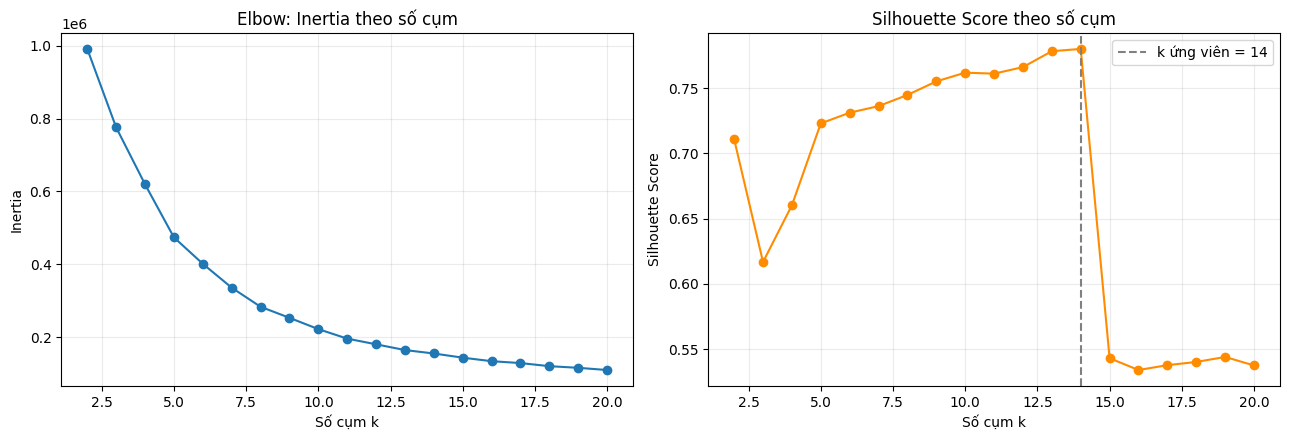

Quy mô và thành phần nhãn tham khảo trong từng cụm:


,Số mẫu,Tỷ lệ (%),Attack phổ biến nhất,Tỷ lệ attack phổ biến (%)
Cluster,,,,
0,13789,68.95,DOS_SYN_Hping,100.00
1,1260,6.30,Thing_Speak,54.76
2,646,3.23,Thing_Speak,72.91
3,346,1.73,NMAP_XMAS_TREE_SCAN,100.00
4,522,2.61,ARP_poisioning,71.65
5,656,3.28,MQTT_Publish,97.26
6,43,0.22,ARP_poisioning,93.02
7,1591,7.95,DOS_SYN_Hping,97.36
8,33,0.16,ARP_poisioning,84.85


Tỷ lệ các Attack_type trong mỗi cụm (chỉ dùng để diễn giải):


Attack_type tham khảo,ARP_poisioning,DDOS_Slowloris,DOS_SYN_Hping,MQTT_Publish,Metasploit_Brute_Force_SSH,NMAP_FIN_SCAN,NMAP_OS_DETECTION,NMAP_TCP_scan,NMAP_UDP_SCAN,NMAP_XMAS_TREE_SCAN,Thing_Speak,Wipro_bulb
Cluster,,,,,,,,,,,,
0,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,0.437,0.000,0.000,0.000,0.002,0.001,0.000,0.000,0.002,0.001,0.548,0.010
2,0.124,0.050,0.000,0.060,0.006,0.000,0.000,0.000,0.000,0.000,0.729,0.031
3,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000
4,0.716,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.241,0.000,0.042,0.000
5,0.015,0.012,0.000,0.973,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
6,0.930,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.070,0.000
7,0.000,0.010,0.974,0.000,0.000,0.000,0.000,0.000,0.016,0.000,0.000,0.000
8,0.848,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.030,0.000,0.121,0.000


Trung vị 10 biến số phân biệt cụm nhiều nhất:


...

Phân bố proto trong từng cụm:


proto,icmp,tcp,udp
Cluster,,,
0,0.000,1.000,0.000
1,0.002,0.001,0.998
2,0.000,0.998,0.002
3,0.000,1.000,0.000
4,0.010,0.000,0.990
5,0.000,1.000,0.000
6,0.000,0.884,0.116
7,0.000,1.000,0.000
8,0.030,0.606,0.364


Phân bố service trong từng cụm:


service,-,dhcp,dns,http,irc,mqtt,ntp,ssh,ssl
Cluster,,,,,,,,,
0,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,0.025,0.003,0.956,0.000,0.000,0.000,0.016,0.000,0.000
2,0.002,0.000,0.000,0.646,0.000,0.060,0.000,0.006,0.286
3,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
4,0.259,0.019,0.720,0.000,0.000,0.000,0.002,0.000,0.000
5,0.009,0.000,0.006,0.012,0.000,0.973,0.000,0.000,0.000
6,0.116,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.884
7,0.974,0.000,0.000,0.026,0.000,0.000,0.000,0.000,0.000
8,0.333,0.000,0.212,0.000,0.000,0.000,0.000,0.000,0.455


Đã lưu metrics, cấu trúc cụm, biểu đồ và mô hình K-Means trong D:\sgu26_machine_learning\DoAnCK\RT_IOT2022_EDA_TienXuLy_TronBo\rt_iot_eda_outputs\models


In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

CLUSTER_SAMPLE_SIZE = min(20_000, len(X_fit))
SILHOUETTE_SAMPLE_SIZE = min(4_000, CLUSTER_SAMPLE_SIZE)
cluster_sample = X_fit.sample(n=CLUSTER_SAMPLE_SIZE, random_state=RANDOM_STATE)

# Fit preprocessing trên train-fit, không dùng validation hoặc test.
cluster_preprocessor = make_preprocessor(scale_numeric=True)
cluster_preprocessor.fit(X_fit)
X_cluster = cluster_preprocessor.transform(cluster_sample)

cluster_results = []
cluster_models = {}
for k in range(2, 21):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    cluster_labels = kmeans.fit_predict(X_cluster)
    cluster_models[k] = kmeans
    cluster_results.append({
        'k': k,
        'Inertia': kmeans.inertia_,
        'Silhouette Score': silhouette_score(
            X_cluster, cluster_labels,
            sample_size=SILHOUETTE_SAMPLE_SIZE,
            random_state=RANDOM_STATE,
        ),
    })

cluster_results = pd.DataFrame(cluster_results)
best_k = int(cluster_results.loc[cluster_results['Silhouette Score'].idxmax(), 'k'])
best_kmeans = cluster_models[best_k]
cluster_labels = best_kmeans.labels_
print(f'Ứng viên k={best_k} có Silhouette Score cao nhất trong dải đã khảo sát.')
if best_k == cluster_results['k'].max():
    print('Lưu ý: Silhouette vẫn cao nhất ở biên trên; cần mở rộng dải k trước khi kết luận.')
display(cluster_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(cluster_results['k'], cluster_results['Inertia'], marker='o')
axes[0].set(title='Elbow: Inertia theo số cụm', xlabel='Số cụm k', ylabel='Inertia')
axes[0].grid(alpha=0.25)
axes[1].plot(cluster_results['k'], cluster_results['Silhouette Score'], marker='o', color='darkorange')
axes[1].axvline(best_k, color='gray', linestyle='--', label=f'k ứng viên = {best_k}')
axes[1].set(title='Silhouette Score theo số cụm', xlabel='Số cụm k', ylabel='Silhouette Score')
axes[1].grid(alpha=0.25)
axes[1].legend()
fig.tight_layout()
fig.savefig(MODEL_DIR / 'clustering_k_selection.png', dpi=160, bbox_inches='tight')
plt.show()

# Chỉ dùng nhãn sau khi fit để diễn giải cấu trúc cụm.
clustered_sample = cluster_sample.copy()
clustered_sample['Cluster'] = cluster_labels
clustered_sample['Attack_type tham khảo'] = y_fit.loc[cluster_sample.index].to_numpy()
cluster_distribution = pd.crosstab(
    clustered_sample['Cluster'], clustered_sample['Attack_type tham khảo'], normalize='index'
)
cluster_sizes = clustered_sample['Cluster'].value_counts().sort_index()
cluster_summary = pd.DataFrame({
    'Số mẫu': cluster_sizes,
    'Tỷ lệ (%)': cluster_sizes / len(clustered_sample) * 100,
})
cluster_summary['Attack phổ biến nhất'] = cluster_distribution.idxmax(axis=1)
cluster_summary['Tỷ lệ attack phổ biến (%)'] = cluster_distribution.max(axis=1) * 100
print('Quy mô và thành phần nhãn tham khảo trong từng cụm:')
display(cluster_summary.round(2))
print('Tỷ lệ các Attack_type trong mỗi cụm (chỉ dùng để diễn giải):')
display(cluster_distribution.round(3))

median_profile = clustered_sample.groupby('Cluster')[num_cols].median()
profile_features = median_profile.std(axis=0).sort_values(ascending=False).head(10).index.tolist()
print('Trung vị 10 biến số phân biệt cụm nhiều nhất:')
display(median_profile[profile_features].round(3))
for column in cat_cols:
    print(f'Phân bố {column} trong từng cụm:')
    display(pd.crosstab(clustered_sample['Cluster'], clustered_sample[column], normalize='index').round(3))

cluster_results.to_csv(MODEL_DIR / 'clustering_metrics.csv', index=False, encoding='utf-8-sig')
cluster_summary.to_csv(MODEL_DIR / 'clustering_summary.csv', encoding='utf-8-sig')
cluster_distribution.to_csv(MODEL_DIR / 'clustering_attack_distribution.csv', encoding='utf-8-sig')
clustered_sample[['Cluster', 'Attack_type tham khảo']].to_csv(
    MODEL_DIR / 'clustering_sample_assignments.csv.gz', index=False,
    compression='gzip', encoding='utf-8-sig'
)
joblib.dump({
    'preprocessor': cluster_preprocessor,
    'model': best_kmeans,
    'feature_columns': X_train_full.columns.tolist(),
    'selected_k': best_k,
}, MODEL_DIR / 'best_kmeans_clustering.joblib', compress=3)
print('Đã lưu metrics, cấu trúc cụm, biểu đồ và mô hình K-Means trong', MODEL_DIR.resolve())

## 5. Phân tích overfitting, underfitting và độ ổn định

Train-validation gap được dùng để xem mô hình có khớp quá mức với tập fit hay không; điểm thấp đồng thời trên train và validation mới gợi ý underfitting. Test chỉ báo cáo cho mô hình đã chọn, không dùng để điều chỉnh mô hình. Độ ổn định được ước lượng bằng ba lần holdout phân tầng với các seed khác nhau; đây là đánh giá ban đầu, chưa thay thế repeated cross-validation.

Ở lần chạy hiện tại, Random Forest đạt Macro-F1 khoảng `1.000` trên train/validation nhưng `0.9773` trên test: chưa thấy gap train-validation, song kết quả test thấp hơn nên cần lưu ý khả năng chênh lệch tổng quát hóa. MLP đạt `0.9702` train và `0.9791` validation, không có dấu hiệu overfitting ở lần chia này; tuy nhiên mô hình chạm `max_iter=40`, nên chưa thể kết luận đã hội tụ hoàn toàn. Điểm train và validation đều cao, vì vậy chưa có bằng chứng rõ về underfitting.

Qua ba seed, Macro-F1 trung bình ± độ lệch chuẩn là khoảng `0.9838 ± 0.0218` với Random Forest và `0.9622 ± 0.0202` với MLP. Weighted-F1 vẫn gần `0.998` trở lên; chênh lệch giữa hai loại metric cho thấy Macro-F1 nhạy hơn với các lớp hiếm. Cần thêm lần chia hoặc repeated cross-validation nếu cần ước lượng độ ổn định chắc chắn hơn.

Train/validation gap: chênh lệch lớn có thể gợi ý overfitting; cả hai điểm thấp có thể gợi ý underfitting.


,Mô hình,Train Macro F1,Validation Macro F1,Train-validation gap,Test Macro F1 (mô hình chọn),Số vòng MLP,Loss cuối MLP,MLP chạm max_iter
0,Random Forest,1.0000,1.0000,0.0000,0.9773,NaN,NaN,NaN
1,Neural Network (MLP),0.9702,0.9791,-0.0089,NaN,40.0,0.0057,True


Độ ổn định trên 3 lần holdout phân tầng:


,Seed,Mô hình,Validation Macro F1,Validation Weighted F1
0,42,Random Forest,1.0000,1.0000
1,42,Neural Network (MLP),0.9791,0.9981
2,52,Random Forest,0.9590,0.9985
3,52,Neural Network (MLP),0.9399,0.9976
4,62,Random Forest,0.9924,0.9988
5,62,Neural Network (MLP),0.9677,0.9979


,Macro F1 trung bình,Độ lệch chuẩn,Thấp nhất,Cao nhất,Biên độ
Mô hình,,,,,
Neural Network (MLP),0.9622,0.0202,0.9399,0.9791,0.0393
Random Forest,0.9838,0.0218,0.9590,1.0000,0.0410


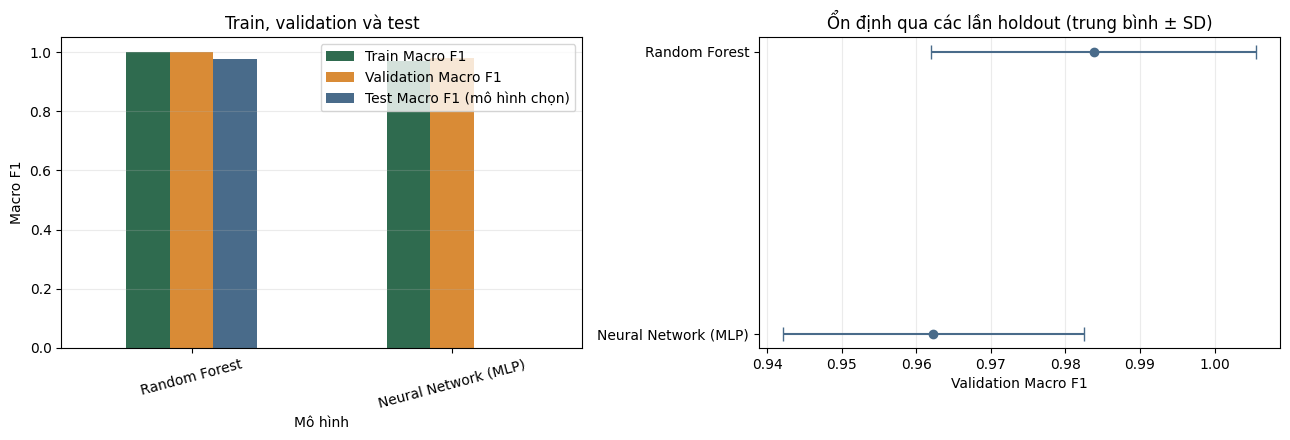

Neural Network (MLP): kết quả dao động đáng chú ý giữa các seed; cần kiểm tra thêm.
Random Forest: kết quả dao động đáng chú ý giữa các seed; cần kiểm tra thêm.
Đã lưu bảng phân tích và biểu đồ overfitting/độ ổn định trong D:\sgu26_machine_learning\DoAnCK\RT_IOT2022_EDA_TienXuLy_TronBo\rt_iot_eda_outputs\models


In [11]:
from sklearn.base import clone

# So sánh điểm trên dữ liệu fit và validation của lần chia ban đầu.
overfit_rows = []
for model_name, pipeline in models.items():
    train_prediction = pipeline.predict(X_fit)
    validation_prediction = pipeline.predict(X_valid)
    train_macro_f1 = f1_score(y_fit, train_prediction, average='macro', zero_division=0)
    validation_macro_f1 = f1_score(y_valid, validation_prediction, average='macro', zero_division=0)
    estimator = pipeline.named_steps['model']
    overfit_rows.append({
        'Mô hình': model_name,
        'Train Macro F1': train_macro_f1,
        'Validation Macro F1': validation_macro_f1,
        'Train-validation gap': train_macro_f1 - validation_macro_f1,
        'Test Macro F1 (mô hình chọn)': test_metrics['macro_f1'] if model_name == best_name else np.nan,
        'Số vòng MLP': getattr(estimator, 'n_iter_', np.nan),
        'Loss cuối MLP': estimator.loss_curve_[-1] if hasattr(estimator, 'loss_curve_') else np.nan,
        'MLP chạm max_iter': (
            estimator.n_iter_ >= estimator.max_iter
            if hasattr(estimator, 'n_iter_') and hasattr(estimator, 'max_iter') else np.nan
        ),
    })

overfit_analysis = pd.DataFrame(overfit_rows).sort_values('Validation Macro F1', ascending=False)
print('Train/validation gap: chênh lệch lớn có thể gợi ý overfitting; cả hai điểm thấp có thể gợi ý underfitting.')
display(overfit_analysis.round(4))

# Repeated holdout: mỗi seed đổi cả phép chia phân tầng và random_state của mô hình.
stability_seeds = [RANDOM_STATE, 52, 62]
stability_rows = []
for seed in stability_seeds:
    if seed == RANDOM_STATE:
        fit_features, validation_features = X_fit, X_valid
        fit_target, validation_target = y_fit, y_valid
        fitted_models = models
    else:
        fit_features, validation_features, fit_target, validation_target = train_test_split(
            X_train_full, y_train_full, test_size=0.15, random_state=seed, stratify=y_train_full
        )
        fitted_models = {}
        for model_name, template in models.items():
            fitted_pipeline = clone(template)
            fitted_pipeline.set_params(model__random_state=seed)
            fitted_pipeline.fit(fit_features, fit_target)
            fitted_models[model_name] = fitted_pipeline

    for model_name, pipeline in fitted_models.items():
        prediction = pipeline.predict(validation_features)
        stability_rows.append({
            'Seed': seed,
            'Mô hình': model_name,
            'Validation Macro F1': f1_score(
                validation_target, prediction, average='macro', zero_division=0
            ),
            'Validation Weighted F1': f1_score(
                validation_target, prediction, average='weighted', zero_division=0
            ),
        })

stability_results = pd.DataFrame(stability_rows)
stability_summary = stability_results.groupby('Mô hình')['Validation Macro F1'].agg(
    ['mean', 'std', 'min', 'max']
).rename(columns={
    'mean': 'Macro F1 trung bình',
    'std': 'Độ lệch chuẩn',
    'min': 'Thấp nhất',
    'max': 'Cao nhất',
})
stability_summary['Biên độ'] = stability_summary['Cao nhất'] - stability_summary['Thấp nhất']
print(f'Độ ổn định trên {len(stability_seeds)} lần holdout phân tầng:')
display(stability_results.round(4))
display(stability_summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
overfit_analysis.set_index('Mô hình')[
    ['Train Macro F1', 'Validation Macro F1', 'Test Macro F1 (mô hình chọn)']
].plot(kind='bar', ax=axes[0], color=['#2f6b4f', '#d98b36', '#496b8a'])
axes[0].set(title='Train, validation và test', ylabel='Macro F1', ylim=(0, 1.05))
axes[0].tick_params(axis='x', rotation=15)
axes[0].grid(axis='y', alpha=0.25)
summary_for_plot = stability_summary.sort_values('Macro F1 trung bình')
axes[1].errorbar(
    summary_for_plot['Macro F1 trung bình'], summary_for_plot.index,
    xerr=summary_for_plot['Độ lệch chuẩn'], fmt='o', capsize=5, color='#496b8a'
)
axes[1].set(title='Ổn định qua các lần holdout (trung bình ± SD)', xlabel='Validation Macro F1')
axes[1].grid(axis='x', alpha=0.25)
fig.tight_layout()
fig.savefig(MODEL_DIR / 'overfitting_stability.png', dpi=160, bbox_inches='tight')
plt.show()

overfit_analysis.to_csv(MODEL_DIR / 'overfitting_analysis.csv', index=False, encoding='utf-8-sig')
stability_results.to_csv(MODEL_DIR / 'stability_runs.csv', index=False, encoding='utf-8-sig')
stability_summary.to_csv(MODEL_DIR / 'stability_summary.csv', encoding='utf-8-sig')
for model_name, row in stability_summary.iterrows():
    if row['Độ lệch chuẩn'] > 0.02:
        print(f'{model_name}: kết quả dao động đáng chú ý giữa các seed; cần kiểm tra thêm.')
    else:
        print(f'{model_name}: kết quả khá nhất quán trong 3 lần holdout này.')
print('Đã lưu bảng phân tích và biểu đồ overfitting/độ ổn định trong', MODEL_DIR.resolve())